# 01 — Fibra óptica: um efeito por vez

Este notebook verifica o integrador da fibra (`simcopy.kernels.ssfm.propagate`)
contra soluções de forma fechada. A equação completa não tem solução geral; por
isso cada seção zera os termos que não interessam, e o efeito isolado passa a ter
solução exata para comparação. A última seção liga todos os termos e verifica o
que continua tendo resposta exata: a energia e a ordem de convergência.

Regras usadas em todas as figuras:

- a física simulada vem **sempre** do pacote (`propagate`); o notebook só escreve a
  forma fechada, que é a referência;
- forma fechada (linha) e simulação (pontos) no mesmo painel, um parâmetro variado
  por vez, e o erro em painel próprio;
- as asserções numéricas ficam nos testes do pytest; cada seção indica qual teste
  garante o resultado mostrado.

Fonte das formas fechadas: Agrawal, *Sistemas de Comunicação por Fibra Óptica* (4ª ed.,
2014), citado pelo número da equação: cap. 2 (fibras), cap. 6 (XPM e FWM entre canais) e
cap. 9 (sóliton). Como no notebook do laser, o texto separa **fato** (com a fonte) de
**dedução** (conta feita aqui a partir de um fato).

## 0. Equação e termos

**[Fato: Agrawal, Eq. 2.6.18]** Com uma polarização, o envelope lento A(z, T) obedece à
equação não linear de Schrödinger (NLS), em que T é o tempo num referencial que anda com o
pulso (Eq. 2.4.8):

$$\frac{\partial A}{\partial z} + \frac{i\beta_2}{2}\frac{\partial^2 A}{\partial T^2}
= -\frac{\alpha}{2}A + i\gamma|A|^2A$$

O pacote resolve a versão vetorial $\mathbf{A} = (A_x, A_y)$, a equação de Manakov:

$$
\frac{\partial \mathbf{A}}{\partial z} =
\underbrace{-\frac{\alpha}{2}\mathbf{A}}_{\text{atenuação}}
\;\underbrace{-\;\frac{i\beta_2}{2}\frac{\partial^2 \mathbf{A}}{\partial T^2}}_{\text{dispersão}}
\;+\;\underbrace{i\gamma\,\tfrac{8}{9}\left(|A_x|^2+|A_y|^2\right)\mathbf{A}}_{\text{Kerr}}
\;+\;\underbrace{\text{PMD}}_{\text{birrefringência aleatória}}
$$

Com uma polarização só e sem o fator 8/9, ela volta a ser a Eq. 2.6.18. O fator 8/9 vem da
média da não linearidade sobre a rotação rápida do estado de polarização (decisão D-2: o
pipeline usa sempre Manakov; a NLS escalar aparece só quando a comparação é com uma forma
fechada escalar; o arquivo VPI usa o mesmo 8/9).

| Seção | α | β₂ | γ | PMD | Forma fechada (Agrawal) |
|---|---|---|---|---|---|
| 1 propagação | 0 | 0 | 0 | 0 | saída = entrada (Eq. 2.4.7 sem dispersão) |
| 2 atenuação | ✓ | 0 | 0 | 0 | $P(z) = P_0 e^{-\alpha z}$ (Eq. 2.5.2) |
| 3 dispersão | 0 | ✓ | 0 | 0 | gaussiana com chirp (Eq. 2.4.16–2.4.19) |
| 4 PMD | 0 | 0 | 0 | ✓ | DGD RMS (Eq. 2.3.16–2.3.17); ‖S‖ = 1 |
| 5 Kerr | ✓/0 | 0/✓ | ✓ | 0 | SPM (2.6.14), sóliton (9.2.8), XPM (2.6.16), FWM (6.3.17) |
| 6 tudo junto | ✓ | ✓ | ✓ | ✓ | energia $e^{-\alpha L}$; erro $\propto h^2$ |

**Convenção de frequência.** **[Fato: Agrawal, Eq. 2.4.3 e 2.4.5]** O campo é
$A\,e^{i(\beta_0 z - \omega_0 t)}$ e a transformada inversa usa $e^{-i\omega t}$; o desvio de
frequência é $\delta\omega = -\partial\phi/\partial t$ (Eq. 2.4.12). **[Dedução]** A FFT
inversa do NumPy usa $e^{+i\omega t}$, então o eixo de frequência da FFT é o do Agrawal com
o sinal trocado: uma componente em $+f$ no eixo da FFT está, fisicamente, em $f_0 - f$
(lado vermelho). A dispersão ($\beta_2\omega^2$) não depende desse sinal; os gráficos de
espectro abaixo usam o eixo da FFT, e cada seção diz quando o sinal importa. (Pergunta em
aberto para o projeto inteiro: `docs/moduladores.md`, dúvida M1.)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from simcopy.core.grid import TimeGrid
from simcopy.core.units import (beta2_from_dispersion, gamma_from_n2,
                                db_per_m_to_np_per_m, frequency_to_wavelength)
from simcopy.kernels.ssfm import propagate, FiberKernelParams

plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.grid": True,
                     "grid.alpha": 0.3, "legend.fontsize": 7.5})
C3 = ["tab:blue", "tab:orange", "tab:green"]
C4 = C3 + ["tab:red"]

# Fibra de referência (valores típicos, Agrawal): todas as seções partem destes valores
# e zeram o que não interessa.
F0 = 193.1e12                                   # Hz, âncora da grade ITU
LAM = frequency_to_wavelength(F0)               # m, λ = c/f
D = 16e-6                                       # s/m² = 16 ps/(nm·km)
B2 = beta2_from_dispersion(D, LAM)              # s²/m (negativo: dispersão anômala)
GAMMA = gamma_from_n2(2.6e-20, 80e-12, LAM)     # 1/(W·m)
ALPHA = db_per_m_to_np_per_m(0.2e-3)            # Np/m = 0,2 dB/km
print(f"λ = {LAM*1e9:.3f} nm | β₂ = {B2*1e27:.2f} ps²/km | "
      f"γ = {GAMMA*1e3:.3f} 1/(W·km) | α = {ALPHA*1e3:.4f} Np/km")

def grade(N, fs):
    """Grade do pacote, com t = 0 no centro da janela."""
    g = TimeGrid(sampling_rate=fs, n_samples=N, t0=-(N // 2) / fs)
    return g.time, g.freq, g.omega

def fibra(L, beta2=0.0, gamma=0.0, alpha=0.0, **kw):
    return FiberKernelParams(length=L, beta2=beta2, gamma=gamma, alpha_np=alpha, **kw)

def erro(ref, sim):
    """Erro relativo no campo complexo: captura amplitude e fase juntas."""
    return np.max(np.abs(sim - ref)) / np.max(np.abs(ref))

def energia(A, dt):
    return np.sum(np.abs(A) ** 2) * dt

def eixo_log_legivel(a, ticks):
    """Eixo x logarítmico com rótulos só nos valores dados."""
    from matplotlib.ticker import FixedLocator, NullLocator, ScalarFormatter
    a.xaxis.set_major_locator(FixedLocator(ticks))
    a.xaxis.set_major_formatter(ScalarFormatter())
    a.xaxis.set_minor_locator(NullLocator())

def gaussiana(t, T0, P0=1.0, C=0.0):
    """A(0,T) = √P0 · exp[-(1 + iC) T² / (2 T0²)]  (Agrawal, Eq. 2.4.10)."""
    return np.sqrt(P0) * np.exp(-(1 + 1j * C) * t ** 2 / (2 * T0 ** 2))

λ = 1552.524 nm | β₂ = -20.47 ps²/km | γ = 1.315 1/(W·km) | α = 0.0461 Np/km


## 1. Propagação sem efeitos: gaussiana e RRC

**Conceito.** Com α = β₂ = γ = 0 a equação se reduz a $\partial\mathbf{A}/\partial z = 0$:
a saída é igual à entrada em qualquer distância (**[Fato: Agrawal, texto após a Eq.
2.4.7]** sem dispersão o pulso se propaga sem mudar de forma). Esse caso não testa física;
testa o encanamento do integrador (FFT, ordem das frequências, meio passo linear duas
vezes). Qualquer erro aqui contaminaria todas as seções seguintes.

Dois formatos de pulso: a gaussiana (usada nas formas fechadas) e o RRC (raiz de
cosseno levantado), que é o formato dos símbolos no transmissor. O RRC é montado
aqui no domínio da frequência, como referência provisória, até o bloco
`PulseShaper` do transmissor existir.

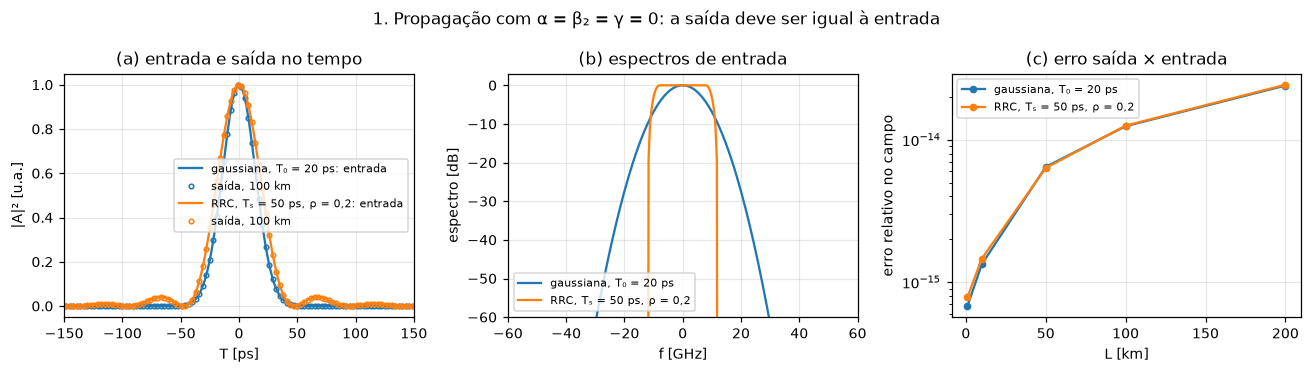

In [2]:
N, FS = 2 ** 12, 2e12                       # dt = 0,5 ps; janela de 2,05 ns
t, f, om = grade(N, FS)
T0 = 20e-12

def rrc(f, Ts, rho):
    """Pulso RRC com roll-off rho: raiz do espectro de cosseno levantado, centrado em t = 0."""
    af = np.abs(f)
    f1, f2 = (1 - rho) / (2 * Ts), (1 + rho) / (2 * Ts)
    H = np.where(af <= f1, 1.0, 0.0)
    banda = (af > f1) & (af <= f2)
    H[banda] = 0.5 * (1 + np.cos(np.pi * Ts / rho * (af[banda] - f1)))
    p = np.fft.fftshift(np.fft.ifft(np.sqrt(H)))
    return (p / np.abs(p).max()).astype(complex)

pulsos = {"gaussiana, T₀ = 20 ps": gaussiana(t, T0),
          "RRC, Tₛ = 50 ps, ρ = 0,2": rrc(f, 50e-12, 0.2)}
Ls = np.array([1e3, 10e3, 50e3, 100e3, 200e3])

fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for i, (nome, A0) in enumerate(pulsos.items()):
    saida = propagate(A0[None, :], om, fibra(100e3))[0]
    ax[0].plot(t * 1e12, np.abs(A0) ** 2, "-", color=C3[i], label=f"{nome}: entrada")
    ax[0].plot(t[::6] * 1e12, np.abs(saida[::6]) ** 2, "o", ms=3, mfc="none",
               color=C3[i], label="saída, 100 km")
    S = np.fft.fftshift(np.abs(np.fft.fft(A0)) ** 2)
    ax[1].plot(np.fft.fftshift(f) / 1e9, 10 * np.log10(S / S.max() + 1e-30), color=C3[i],
               label=nome)
    ax[2].semilogy(Ls / 1e3, [erro(A0, propagate(A0[None, :], om, fibra(L))[0]) + 1e-18
                              for L in Ls], "o-", ms=4, color=C3[i], label=nome)
ax[0].set(xlim=(-150, 150), xlabel="T [ps]", ylabel="|A|² [u.a.]",
          title="(a) entrada e saída no tempo")
ax[1].set(xlim=(-60, 60), ylim=(-60, 3), xlabel="f [GHz]", ylabel="espectro [dB]",
          title="(b) espectros de entrada")
ax[2].set(xlabel="L [km]", ylabel="erro relativo no campo", title="(c) erro saída × entrada")
for a in ax: a.legend()
fig.suptitle("1. Propagação com α = β₂ = γ = 0: a saída deve ser igual à entrada")
fig.tight_layout()

**Leitura.** Cada passo (FFT, multiplicação, FFT inversa) acrescenta um erro de
arredondamento da ordem de 1e-16, que é a precisão dupla. O erro em (c) cresce com o
número de passos (um a cada 5 km) e chega a ~1e-14 em 200 km: é acúmulo de
arredondamento, não física. O RRC tem espectro limitado em
$(1+\rho)/(2T_s) = 12$ GHz e oscilações no tempo (os cruzamentos por zero a cada
$T_s$ são o que zera a interferência entre símbolos depois do filtro casado).

## 2. Atenuação

**Equação** (β₂ = γ = 0): $\partial A/\partial z = -\tfrac{\alpha}{2}A$, com solução
$A(z,T) = A(0,T)\,e^{-\alpha z/2}$. **[Fato: Agrawal, Eq. 2.5.1–2.5.2]** A potência segue a
lei de Beer, $dP/dz = -\alpha P$, e cai como $P(z) = P_0 e^{-\alpha z}$; a forma do pulso
não muda. Em decibéis a queda é linear: 0,2 dB/km dá 20 dB em 100 km.

**[Fato: Agrawal, Eq. 2.5.3]** $\alpha_{dB/km} = -\tfrac{10}{L}\log_{10}(P_{out}/P_{in})
\approx 4{,}343\,\alpha$. O pacote guarda a atenuação em dB/m na configuração e entrega α
em Np/m ao kernel ($\alpha = \alpha_{dB}\,\ln 10 / 10$, e $10/\ln 10 = 4{,}343$).

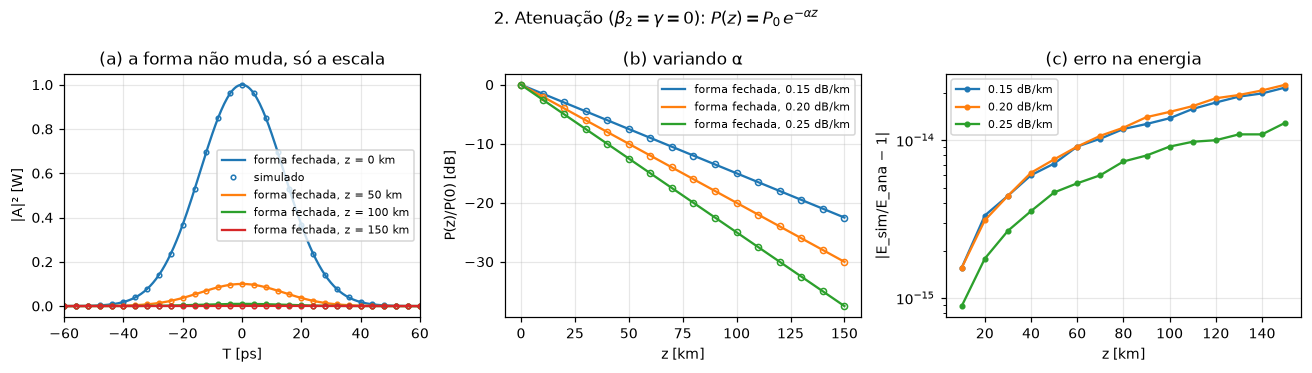

In [3]:
A0 = gaussiana(t, T0)
dt = 1 / FS
zs = np.linspace(0, 150e3, 16)
fig, ax = plt.subplots(1, 3, figsize=(12, 3.4))
for i, z in enumerate([0, 50e3, 100e3, 150e3]):
    s = propagate(A0[None, :], om, fibra(z, alpha=ALPHA))[0]
    ax[0].plot(t * 1e12, np.abs(A0 * np.exp(-ALPHA * z / 2)) ** 2, "-", color=C4[i],
               label=f"forma fechada, z = {z/1e3:.0f} km")
    ax[0].plot(t[::8] * 1e12, np.abs(s[::8]) ** 2, "o", ms=3, mfc="none", color=C4[i],
               label="simulado" if i == 0 else None)
for i, adb in enumerate([0.15e-3, 0.20e-3, 0.25e-3]):
    a = db_per_m_to_np_per_m(adb)
    E = np.array([energia(propagate(A0[None, :], om, fibra(z, alpha=a))[0], dt) for z in zs])
    E_ana = energia(A0, dt) * np.exp(-a * zs)
    ax[1].plot(zs / 1e3, 10 * np.log10(E_ana / E_ana[0]), "-", color=C3[i],
               label=f"forma fechada, {adb*1e3:.2f} dB/km")
    ax[1].plot(zs / 1e3, 10 * np.log10(E / E[0]), "o", ms=4, mfc="none", color=C3[i])
    ax[2].semilogy(zs[1:] / 1e3, np.abs(E[1:] / E_ana[1:] - 1) + 1e-18, "o-", ms=3,
                   color=C3[i], label=f"{adb*1e3:.2f} dB/km")
ax[0].set(xlim=(-60, 60), xlabel="T [ps]", ylabel="|A|² [W]",
          title="(a) a forma não muda, só a escala")
ax[1].set(xlabel="z [km]", ylabel="P(z)/P(0) [dB]", title="(b) variando α")
ax[2].set(xlabel="z [km]", ylabel="|E_sim/E_ana − 1|", title="(c) erro na energia")
for a_ in ax: a_.legend()
fig.suptitle(r"2. Atenuação ($\beta_2 = \gamma = 0$): $P(z) = P_0\,e^{-\alpha z}$")
fig.tight_layout()

**Leitura.** As retas em (b) têm inclinação igual ao coeficiente em dB/km, e o erro em
(c) fica no arredondamento. O operador linear aplica $e^{-\alpha\,dz/4}$ em cada meio
passo (duas vezes por passo, sobre o campo), o que dá exatamente $e^{-\alpha z/2}$ no
campo para qualquer tamanho de passo.

Teste que garante: `test_01_atenuacao.py` (inclui comprimento que não é múltiplo do
passo, o bug 3 do histórico).

## 3. Dispersão cromática

**Equação** (α = γ = 0): $\partial A/\partial z = -\tfrac{i\beta_2}{2}\,\partial^2 A/\partial T^2$.
No domínio da frequência cada componente só ganha fase:
$\tilde A(z,\omega) = \tilde A(0,\omega)\,e^{\,i\beta_2\omega^2 z/2}$. Dessa forma o
módulo do espectro não muda; o que muda é a fase espectral, quadrática em ω, e é ela
que alarga o pulso no tempo (componentes de frequências diferentes chegam em tempos
diferentes).

**[Fato: Agrawal, Eq. 2.4.10, 2.4.16 e 2.4.17]** Para a gaussiana com chirp inicial C,
$A(0,T) = A_0\exp[-(1+iC)T^2/(2T_0^2)]$:

$$A(z,T) = \frac{A_0}{\sqrt{Q(z)}}\exp\!\left[-\frac{(1+iC)\,T^2}{2T_0^2\,Q(z)}\right],\qquad
Q(z) = 1 + (C - i)\frac{\beta_2 z}{T_0^2}$$

$$\frac{T_1}{T_0} = \sqrt{\left(1+\frac{C\beta_2 z}{T_0^2}\right)^2+\left(\frac{\beta_2 z}{T_0^2}\right)^2},
\qquad L_D = \frac{T_0^2}{|\beta_2|}$$

**[Fato: Agrawal, Eq. 2.4.18–2.4.19]** Com $\beta_2 C < 0$ o pulso primeiro comprime, até
$T_1^{min} = T_0/\sqrt{1+C^2}$ em $z_{min} = [|C|/(1+C^2)]\,L_D$, e depois alarga. Esse caso
existe no teste porque o alargamento sem chirp depende só de $|\beta_2|$: um erro de sinal
na dispersão passaria despercebido sem ele. **[Fato: Agrawal, legenda da Fig. 2.11]** Em
dispersão normal as curvas são as mesmas com o sinal de C trocado.

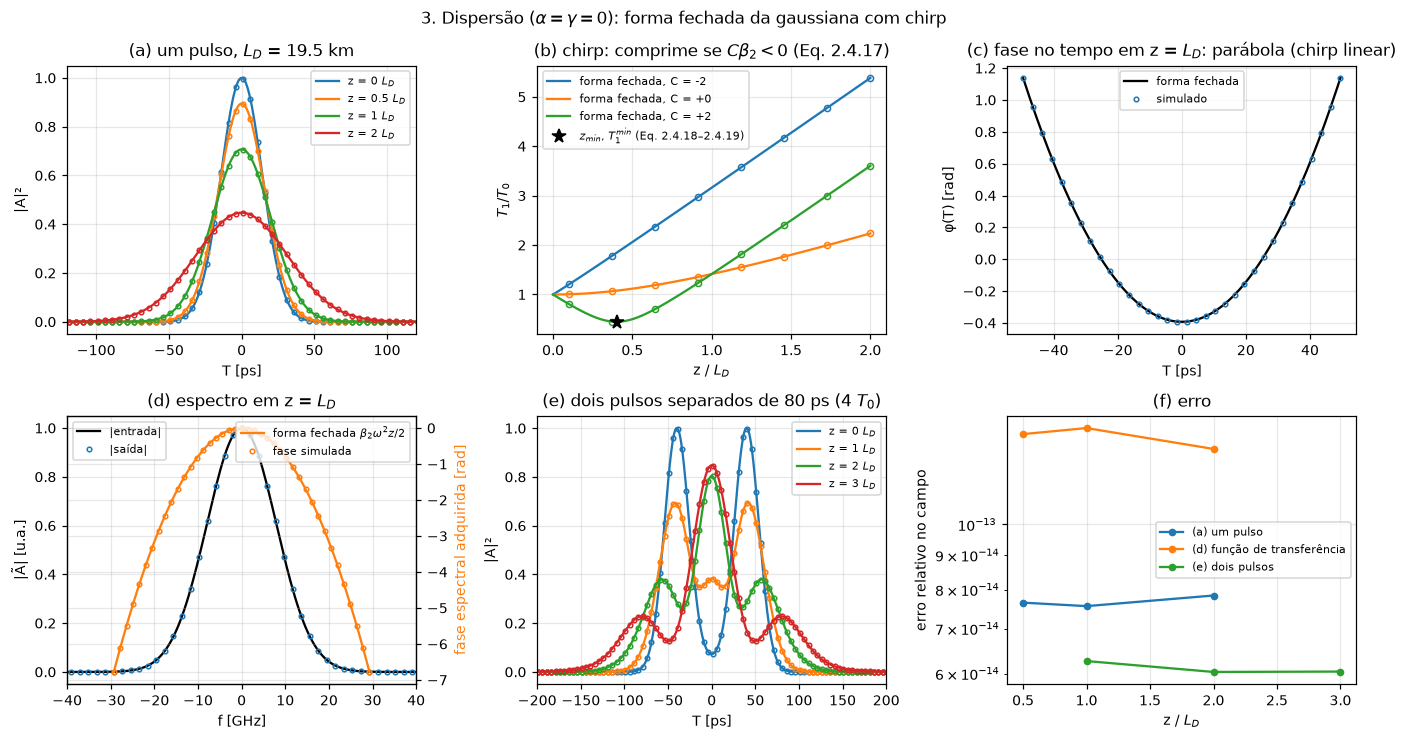

In [4]:
def gauss_ana(T, T0, z, b2, C=0.0):
    """Agrawal, Eq. 2.4.16 com A0 = 1."""
    Q = 1 + (C - 1j) * b2 * z / T0 ** 2
    return np.exp(-(1 + 1j * C) * T ** 2 / (2 * T0 ** 2 * Q)) / np.sqrt(Q)

def largura(t, A):
    """T1 a partir da largura rms da intensidade: para gaussiana, T1 = √2·σ."""
    I = np.abs(A) ** 2
    tc = np.sum(I * t) / np.sum(I)
    return np.sqrt(2 * np.sum(I * (t - tc) ** 2) / np.sum(I))

LD = T0 ** 2 / abs(B2)
sim = lambda A, z: propagate(A[None, :], om, fibra(z, beta2=B2), max_step=max(z, 1) / 200)[0]

fig, ax = plt.subplots(2, 3, figsize=(12.5, 6.8))
erros = {}
# (a) perfis de um pulso em várias distâncias
for i, zr in enumerate([0, 0.5, 1, 2]):
    a, s = gauss_ana(t, T0, zr * LD, B2), sim(gaussiana(t, T0), zr * LD)
    ax[0, 0].plot(t * 1e12, np.abs(a) ** 2, "-", color=C4[i], label=f"z = {zr} $L_D$")
    ax[0, 0].plot(t[::10] * 1e12, np.abs(s[::10]) ** 2, "o", ms=3, mfc="none", color=C4[i])
    if zr > 0:
        erros.setdefault("(a) um pulso", []).append((zr, erro(a, s)))
ax[0, 0].set(xlim=(-120, 120), xlabel="T [ps]", ylabel="|A|²",
             title=f"(a) um pulso, $L_D$ = {LD/1e3:.1f} km")
# (b) largura × distância variando o chirp
zz = np.linspace(0, 2, 80) * LD
zp = np.linspace(0.1, 2, 8) * LD
for i, C in enumerate([-2.0, 0.0, 2.0]):
    ana = np.sqrt((1 + C * B2 * zz / T0 ** 2) ** 2 + (B2 * zz / T0 ** 2) ** 2)
    ax[0, 1].plot(zz / LD, ana, "-", color=C3[i], label=f"forma fechada, C = {C:+.0f}")
    ax[0, 1].plot(zp / LD, [largura(t, sim(gaussiana(t, T0, C=C), z)) / T0 for z in zp],
                  "o", ms=4, mfc="none", color=C3[i])
C_min = 2.0                                       # β₂ < 0: C = +2 comprime
ax[0, 1].plot(C_min / (1 + C_min ** 2), 1 / np.sqrt(1 + C_min ** 2), "k*", ms=9,
              label=r"$z_{min}$, $T_1^{min}$ (Eq. 2.4.18–2.4.19)")
ax[0, 1].set(xlabel="z / $L_D$", ylabel="$T_1/T_0$",
             title=r"(b) chirp: comprime se $C\beta_2 < 0$ (Eq. 2.4.17)")
# (c) fase no tempo em z = L_D
a, s = gauss_ana(t, T0, LD, B2), sim(gaussiana(t, T0), LD)
janela = np.abs(t) < 2.5 * T0
ax[0, 2].plot(t[janela] * 1e12, np.unwrap(np.angle(a[janela])), "-", color="k",
              label="forma fechada")
ax[0, 2].plot(t[janela][::6] * 1e12, np.unwrap(np.angle(s[janela]))[::6], "o", ms=3,
              mfc="none", color=C3[0], label="simulado")
ax[0, 2].set(xlabel="T [ps]", ylabel="φ(T) [rad]",
             title="(c) fase no tempo em z = $L_D$: parábola (chirp linear)")
# (d) espectro: módulo igual, fase quadrática
z = LD
Sin, Sout = np.fft.fft(gaussiana(t, T0)), np.fft.fft(sim(gaussiana(t, T0), z))
k = np.argsort(f)
banda = np.abs(Sin[k]) > 1e-3 * np.abs(Sin).max()
ax[1, 0].plot(f[k] / 1e9, np.abs(Sin[k]) / np.abs(Sin).max(), "-", color="k", label="|entrada|")
ax[1, 0].plot(f[k][::4] / 1e9, np.abs(Sout[k][::4]) / np.abs(Sin).max(), "o", ms=3,
              mfc="none", color=C3[0], label="|saída|")
ax2 = ax[1, 0].twinx()
ax2.plot(f[k][banda] / 1e9, 0.5 * B2 * om[k][banda] ** 2 * z, "-", color=C3[1],
         label=r"forma fechada $\beta_2\omega^2 z/2$")
fase = np.unwrap(np.angle(Sout[k][banda] / Sin[k][banda]))
centro = np.argmin(np.abs(f[k][banda]))           # ancora o unwrap em f = 0 (fase 0 lá)
fase -= 2 * np.pi * np.round(fase[centro] / (2 * np.pi))
ax2.plot(f[k][banda][::3] / 1e9, fase[::3], "o", ms=3, mfc="none", color=C3[1],
         label="fase simulada")
ax2.set_ylabel("fase espectral adquirida [rad]", color=C3[1])
ax[1, 0].set(xlim=(-40, 40), xlabel="f [GHz]", ylabel="|Ã| [u.a.]",
             title="(d) espectro em z = $L_D$")
ax2.legend(loc="upper right")
erros["(d) função de transferência"] = [
    (zr, np.max(np.abs(np.fft.fft(sim(gaussiana(t, T0), zr * LD))
                       - Sin * np.exp(0.5j * B2 * om ** 2 * zr * LD))) / np.abs(Sin).max())
    for zr in [0.5, 1, 2]]
# (e) dois pulsos com o mesmo λ: alargam e passam a se sobrepor
sep = 4 * T0
dois = lambda z: (gauss_ana(t - sep / 2, T0, z, B2) + gauss_ana(t + sep / 2, T0, z, B2))
for i, zr in enumerate([0, 1, 2, 3]):
    a, s = dois(zr * LD), sim(dois(0), zr * LD)
    ax[1, 1].plot(t * 1e12, np.abs(a) ** 2, "-", color=C4[i], label=f"z = {zr} $L_D$")
    ax[1, 1].plot(t[::10] * 1e12, np.abs(s[::10]) ** 2, "o", ms=3, mfc="none", color=C4[i])
    if zr > 0:
        erros.setdefault("(e) dois pulsos", []).append((zr, erro(a, s)))
ax[1, 1].set(xlim=(-200, 200), xlabel="T [ps]", ylabel="|A|²",
             title=f"(e) dois pulsos separados de {sep*1e12:.0f} ps (4 $T_0$)")
# (f) erro
for i, (nome, pts) in enumerate(erros.items()):
    zr, e = zip(*pts)
    ax[1, 2].semilogy(zr, np.array(e) + 1e-18, "o-", ms=4, color=C3[i], label=nome)
ax[1, 2].set(xlabel="z / $L_D$", ylabel="erro relativo no campo", title="(f) erro")
for a_ in [ax[0, 0], ax[0, 1], ax[0, 2], ax[1, 1], ax[1, 2]]: a_.legend()
ax[1, 0].legend(loc="upper left")
fig.suptitle(r"3. Dispersão ($\alpha = \gamma = 0$): forma fechada da gaussiana com chirp")
fig.tight_layout()

**Leitura.**
- (b) Só o sinal de β₂ do pacote (negativo para D > 0) faz C = +2 comprimir; com o sinal
  trocado, as curvas de C = +2 e C = −2 trocariam de lugar. O mínimo cai na estrela das
  Eq. 2.4.18–2.4.19 ($z_{min} = 0{,}4\,L_D$, $T_1^{min} = 0{,}447\,T_0$), e as três curvas
  repetem a Fig. 2.11(a) do Agrawal.
- (c) A fase no tempo é parabólica: pela Eq. 2.4.12 a frequência $\delta\omega = -\partial
  \phi/\partial T$ varia linearmente ao longo do pulso. É o chirp induzido pela dispersão:
  **[Fato: Agrawal, texto após a Eq. 2.4.16]** o parâmetro de chirp passa de C para
  $C_1(z) = C + (1+C^2)\beta_2 z/T_0^2$, que vale −1 em $z = L_D$ para C = 0 e β₂ < 0.
- (d) O módulo do espectro não muda e a fase adquirida é $\beta_2\omega^2 z/2$; o erro da
  função de transferência inteira está em (f).
- (e) Os dois pulsos começam separados e, ao alargar, passam a se sobrepor. Na região
  de sobreposição os campos se somam com fases diferentes (cada pulso tem o próprio
  chirp), e a intensidade deixa de ser a soma das intensidades. A forma fechada é a
  soma dos dois campos, porque a equação é linear quando γ = 0. Essa sobreposição é a
  interferência entre símbolos que a compensação de dispersão do receptor precisa desfazer.

Teste que garante: `test_02_dispersao.py` (largura, chirp e o sinal de β₂).

## 4. PMD: estado de polarização na esfera de Poincaré

**Conceito.** A birrefringência da fibra varia aleatoriamente ao longo do comprimento.
O pacote modela a fibra como uma sequência de seções de comprimento $L_{corr}$: em cada
fronteira o estado de polarização sofre uma rotação aleatória uniforme (matriz de SU(2))
e, dentro de cada passo, as duas polarizações principais ganham um atraso diferencial
(DGD). Como a rotação é unitária, cada componente de frequência continua totalmente
polarizada: o vetor de Stokes normalizado tem módulo 1. Como o DGD multiplica a
frequência, componentes de frequências diferentes saem com estados diferentes.

Vetor de Stokes (normalizado por $S_0 = |X|^2+|Y|^2$):
$S_1 = |X|^2-|Y|^2$, $S_2 = 2\,\mathrm{Re}(XY^*)$, $S_3 = -2\,\mathrm{Im}(XY^*)$
(o sinal de $S_3$ varia entre autores).

**Todas as entradas precisam ser vetoriais para PMD:** `propagate` só aplica PMD se o
campo tiver duas polarizações, forma (2, N). Com forma (1, N) a PMD é ignorada sem aviso
(verificado na primeira célula abaixo).

**Evolução ao longo de z.** `propagate` devolve só o campo no fim da fibra. Sem não
linearidade o passo é fixo; propagar até cada $z_k$ (múltiplo do passo) com a mesma seed
repete a mesma sequência de passos e de sorteios, e portanto reproduz o início da mesma
realização. Uma opção do kernel para devolver o campo em posições escolhidas tornaria
isso direto (decisão pendente).

campo (1, N): erro saída × entrada = 1.2750230063848771e-14 → a PMD não foi aplicada


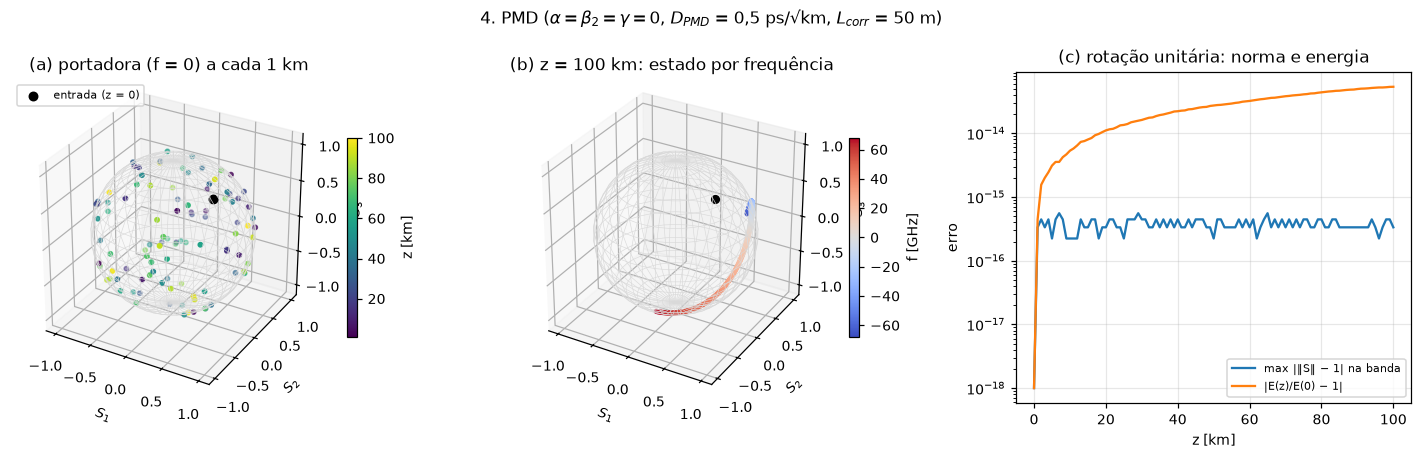

In [5]:
T0p, DPMD, PASSO = 5e-12, 0.5e-12 / np.sqrt(1e3), 1e3   # 0,5 ps/√km: exagerado para visualização
Ap = gaussiana(t, T0p)
entrada = np.vstack([Ap, Ap]) / np.sqrt(2)               # linear a 45°
pmd = lambda z: fibra(z, pmd_coefficient=DPMD, correlation_length=50.0)
rodar = lambda z, seed=7: propagate(entrada, om, pmd(z), rng=np.random.default_rng(seed),
                                    max_step=PASSO)

escalar = propagate(Ap[None, :] / np.sqrt(2), om, pmd(100e3), rng=np.random.default_rng(7))
print("campo (1, N): erro saída × entrada =", erro(Ap / np.sqrt(2), escalar[0]),
      "→ a PMD não foi aplicada")

def stokes(X, Y):
    S0 = np.abs(X) ** 2 + np.abs(Y) ** 2
    return np.array([np.abs(X) ** 2 - np.abs(Y) ** 2, 2 * np.real(X * np.conj(Y)),
                     -2 * np.imag(X * np.conj(Y))]) / S0

zk = np.arange(0, 101e3, PASSO)
saidas = [rodar(z) for z in zk]
Xf = [np.fft.fft(s[0]) for s in saidas]
Yf = [np.fft.fft(s[1]) for s in saidas]
S_portadora = np.array([stokes(X[0], Y[0]) for X, Y in zip(Xf, Yf)])          # f = 0
espectro = np.abs(Xf[-1]) ** 2 + np.abs(Yf[-1]) ** 2
bins = np.where(espectro > 0.01 * espectro.max())[0]
S_freq = stokes(Xf[-1][bins], Yf[-1][bins])
erro_norma = [np.max(np.abs(np.linalg.norm(stokes(X[bins], Y[bins]), axis=0) - 1))
              for X, Y in zip(Xf, Yf)]
erro_energia = [abs(energia(s, dt) / energia(entrada, dt) - 1) for s in saidas]

def esfera(a):
    u, v = np.mgrid[0:2 * np.pi:40j, 0:np.pi:20j]
    a.plot_wireframe(np.cos(u) * np.sin(v), np.sin(u) * np.sin(v), np.cos(v),
                     color="0.85", lw=0.4)
    a.set(xlabel="$S_1$", ylabel="$S_2$", zlabel="$S_3$", box_aspect=(1, 1, 1))

fig = plt.figure(figsize=(13, 4.2))
a1 = fig.add_subplot(1, 3, 1, projection="3d"); esfera(a1)
sz = a1.scatter(*S_portadora[1:].T, c=zk[1:] / 1e3, cmap="viridis", s=8)
a1.scatter(*S_portadora[0], color="k", s=30, label="entrada (z = 0)")
fig.colorbar(sz, ax=a1, shrink=0.6, label="z [km]")
a1.set_title("(a) portadora (f = 0) a cada 1 km")
a1.legend(loc="upper left")
a2 = fig.add_subplot(1, 3, 2, projection="3d"); esfera(a2)
sc = a2.scatter(*S_freq, c=f[bins] / 1e9, cmap="coolwarm", s=6)
a2.scatter(*S_portadora[0], color="k", s=25)
fig.colorbar(sc, ax=a2, shrink=0.6, label="f [GHz]")
a2.set_title("(b) z = 100 km: estado por frequência")
a3 = fig.add_subplot(1, 3, 3)
a3.semilogy(zk / 1e3, np.array(erro_norma) + 1e-18, "-", color=C3[0],
            label="max |‖S‖ − 1| na banda")
a3.semilogy(zk / 1e3, np.array(erro_energia) + 1e-18, "-", color=C3[1],
            label="|E(z)/E(0) − 1|")
a3.set(xlabel="z [km]", ylabel="erro", title="(c) rotação unitária: norma e energia")
a3.legend()
fig.suptitle("4. PMD ($\\alpha = \\beta_2 = \\gamma = 0$, $D_{PMD}$ = 0,5 ps/√km, "
             "$L_{corr}$ = 50 m)")
fig.tight_layout()

**Leitura.**
- (a) A cada 1 km o estado da portadora está em um ponto diferente da superfície da
  esfera: continua totalmente polarizado, mas a orientação não guarda memória da
  anterior. Isso decorre do modelo: cada fronteira de seção sorteia uma rotação
  uniforme e independente, então pontos separados por mais de $L_{corr}$ são
  independentes e cobrem a esfera de modo uniforme (é o que `test_04_pmd.py::test_d`
  verifica). Em escala de quilômetros isso corresponde à fibra real, cujo estado se
  descorrelaciona em dezenas de metros. Abaixo de $L_{corr}$ o modelo não representa a
  evolução contínua do estado: dentro de uma seção a portadora não muda e na fronteira
  salta. Ver a mudança gradual pediria um modelo de birrefringência contínua (pendente).
- (b) Na saída, as frequências do pulso ocupam um arco: com DGD, o estado depende da
  frequência. Na entrada, todas estavam no mesmo ponto (preto). Quanto maior o DGD
  acumulado ou a banda do sinal, maior o arco; por isso a PMD pesa mais em taxas altas.
- (c) Norma de Stokes e energia ficam no arredondamento, o que verifica que rotação e
  DGD são unitários.

### 4.1 Estatística do DGD

**[Fato: Agrawal, Eq. 2.3.15–2.3.17]** O atraso diferencial de grupo (DGD) entre os dois
estados principais de polarização é aleatório. Seu valor RMS, com $l_c$ o comprimento de
correlação da birrefringência, é

$$\sigma_T^2(z) = 2(\Delta\beta_1)^2 l_c^2\left[e^{-z/l_c} + z/l_c - 1\right],\qquad
\sigma_T \approx \Delta\beta_1\sqrt{2 l_c L} \equiv D_p\sqrt{L}\quad (z \gg l_c)$$

e, para $z \ll l_c$, $\sigma_T = \Delta\beta_1 z$ (fibra de birrefringência constante,
Eq. 2.3.15). O pacote usa a mesma definição: `pmd_coefficient` é $D_p$ do valor **RMS**.

O DGD de uma realização é medido pela matriz de Jones em duas frequências vizinhas
(`simcopy.testing.fisica.jones_dgd`, a mesma função dos testes). A fibra é a da seção 4
($D_p$ = 0,5 ps/√km, $l_c$ = 50 m), com passo de 1 km.

L =   0.005 km: RMS = 0.0112 ps | D_p√L = 0.0354 ps | Eq. 2.3.16 = 0.0078 ps
L =   0.020 km: RMS = 0.0447 ps | D_p√L = 0.0707 ps | Eq. 2.3.16 = 0.0296 ps
L =   0.050 km: RMS = 0.1118 ps | D_p√L = 0.1118 ps | Eq. 2.3.16 = 0.0678 ps
L =   0.200 km: RMS = 0.2236 ps | D_p√L = 0.2236 ps | Eq. 2.3.16 = 0.1942 ps
L =   1.000 km: RMS = 0.5000 ps | D_p√L = 0.5000 ps | Eq. 2.3.16 = 0.4873 ps
L =   5.000 km: RMS = 1.1711 ps | D_p√L = 1.1180 ps | Eq. 2.3.16 = 1.1124 ps
L =  20.000 km: RMS = 2.2370 ps | D_p√L = 2.2361 ps | Eq. 2.3.16 = 2.2333 ps
L = 100.000 km: RMS = 5.0539 ps | D_p√L = 5.0000 ps | Eq. 2.3.16 = 4.9987 ps
20 km: <τ>/τ_rms = 0.923 (maxwelliana: 0.921)


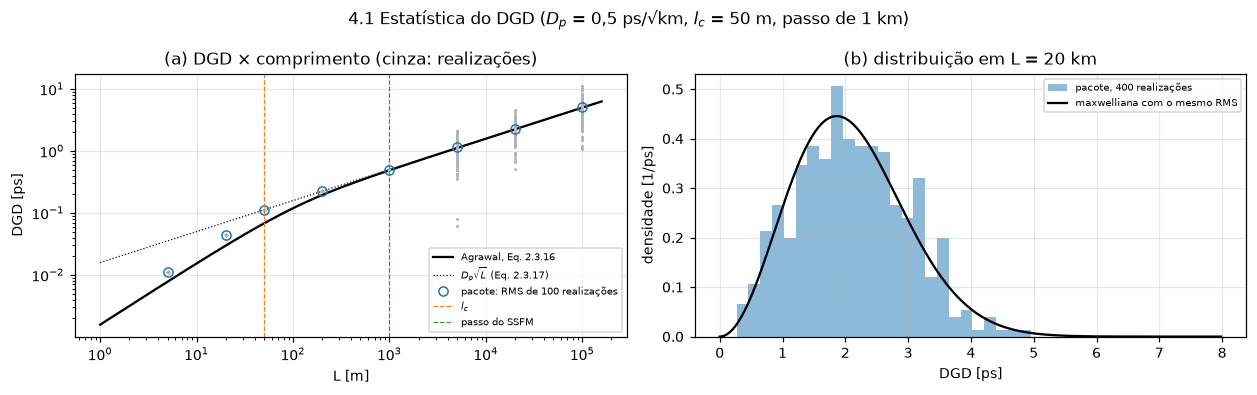

In [6]:
from simcopy.testing.fisica import jones_dgd

DFj, NSj = 1.25e9, 64                       # grade curta: só o DGD interessa
OMj = 2 * np.pi * np.fft.fftfreq(NSj, 1 / (NSj * DFj))
LC = 50.0

def dgds(L, n, passo=PASSO):
    run = lambda A, r: propagate(A, OMj, pmd(L), rng=np.random.default_rng(10_000 + r),
                                 max_step=min(passo, L))
    return jones_dgd(run, n, DFj, NSj)

L_pmd = np.array([5, 20, 50, 200, 1e3, 5e3, 20e3, 100e3])
amostras = [dgds(L, 100) for L in L_pmd]
rms = np.array([np.sqrt(np.mean(a ** 2)) for a in amostras])
L_eixo = np.logspace(0, 5.2, 200)
db1 = DPMD / np.sqrt(2 * LC)                                  # Δβ₁ = D_p/√(2 l_c)
sigma_ag = np.sqrt(2 * db1 ** 2 * LC ** 2 * (np.exp(-L_eixo / LC) + L_eixo / LC - 1))
tau20 = dgds(20e3, 400)
s20 = np.sqrt(np.mean(tau20 ** 2))

fig, ax = plt.subplots(1, 2, figsize=(11.5, 3.6))
ax[0].loglog(L_eixo, sigma_ag * 1e12, "k-", label="Agrawal, Eq. 2.3.16")
ax[0].loglog(L_eixo, DPMD * np.sqrt(L_eixo) * 1e12, "k:", lw=0.8, label=r"$D_p\sqrt{L}$ (Eq. 2.3.17)")
for L, a in zip(L_pmd, amostras):
    ax[0].loglog(np.full(a.size, L), a * 1e12, ".", ms=2, color="0.7")
ax[0].loglog(L_pmd, rms * 1e12, "o", mfc="none", color=C3[0], label="pacote: RMS de 100 realizações")
ax[0].axvline(LC, color=C3[1], ls="--", lw=0.8, label="$l_c$")
ax[0].axvline(PASSO, color=C3[2], ls="--", lw=0.8, label="passo do SSFM")
ax[0].set(xlabel="L [m]", ylabel="DGD [ps]", title="(a) DGD × comprimento (cinza: realizações)")
x = np.linspace(0, 3.5 * s20, 200) * 1e12
a_mx = s20 / np.sqrt(3) * 1e12                                # Maxwell: σ_rms² = 3a²
ax[1].hist(tau20 * 1e12, bins=25, density=True, color=C3[0], alpha=0.5,
           label="pacote, 400 realizações")
ax[1].plot(x, np.sqrt(2 / np.pi) * x ** 2 / a_mx ** 3 * np.exp(-x ** 2 / (2 * a_mx ** 2)),
           "k-", label="maxwelliana com o mesmo RMS")
ax[1].set(xlabel="DGD [ps]", ylabel="densidade [1/ps]", title="(b) distribuição em L = 20 km")
for a_ in ax: a_.legend(fontsize=6.5)
fig.suptitle("4.1 Estatística do DGD ($D_p$ = 0,5 ps/√km, $l_c$ = 50 m, passo de 1 km)")
fig.tight_layout()
for L, r in zip(L_pmd, rms):
    print(f"L = {L/1e3:7.3f} km: RMS = {r*1e12:.4f} ps | D_p√L = {DPMD*np.sqrt(L)*1e12:.4f} ps | "
          f"Eq. 2.3.16 = {np.sqrt(2*db1**2*LC**2*(np.exp(-L/LC)+L/LC-1))*1e12:.4f} ps")
print(f"20 km: <τ>/τ_rms = {np.mean(tau20)/s20:.3f} (maxwelliana: {np.sqrt(8/(3*np.pi)):.3f})")

**Leitura.** (Os números citados estão na saída da célula.)
- Para $L \gg l_c$ o RMS segue $D_p\sqrt{L}$, a Eq. 2.3.17, que é o regime dos enlaces
  (dezenas de km contra $l_c$ = 50 m).
- Perto e abaixo de $l_c$ o modelo do pacote fica acima da Eq. 2.3.16: $\sqrt{2}$ vezes
  para $z \ll l_c$, 1,65 vezes em $z = l_c$ e 1,15 vezes em 200 m. São modelos diferentes do
  mesmo fenômeno: o pacote usa seções discretas de comprimento $l_c$ com rotação abrupta
  entre elas; o Agrawal, birrefringência com correlação exponencial. O teste
  `test_04_pmd.py` só verifica o regime longo (o texto dele fala em "até √2"; o máximo é
  1,65, em $z = l_c$).
- **[Fato: verificado rodando]** Até o tamanho do passo do SSFM (1 km aqui) as 100
  realizações dão **o mesmo DGD**, sem espalhamento (pontos cinza sobrepostos). Quando a
  fibra inteira cabe em um passo, o modelo de passo grosso aplica um único elemento de DGD
  com módulo fixo ($D_p L/\sqrt{l_c}$ abaixo de $l_c$, $D_p\sqrt{L}$ acima); só a
  orientação é sorteada. A distribuição aparece quando há vários passos: em 20 km (20 passos), (b)
  segue a maxwelliana, a distribuição que `test_04_pmd.py::test_c` verifica (o Agrawal não
  a deduz). Consequência prática: para fibras curtas, o passo máximo precisa ser menor
  que a fibra para o DGD ser aleatório.

Testes que garantem: `test_04_pmd.py` (RMS ∝ √z, independência do passo, maxwelliana,
rotação uniforme na esfera).

## 5. Efeito Kerr

### 5.1 Automodulação de fase (SPM), sem dispersão

**Equação** (β₂ = 0, escalar): $\partial A/\partial z = -\tfrac{\alpha}{2}A + i\gamma|A|^2A$.
Sem dispersão a intensidade de cada instante só decai com α, e a fase cresce com a
própria intensidade.

**[Fato: Agrawal, Eq. 2.6.13, 2.6.14 e 2.6.7]** $\gamma = 2\pi\bar n_2/(A_{eff}\lambda)$, e o
deslocamento de fase não linear é $\phi_{NL} = \gamma P_{in} L_{eff}$, com
$L_{eff} = [1 - e^{-\alpha L}]/\alpha$. Com $P_{in}$ variando no tempo, $\phi_{NL}$ segue a
forma do pulso:

$$A(L,T) = A(0,T)\,e^{-\alpha L/2}\exp\!\left[i\gamma|A(0,T)|^2 L_{eff}\right]$$

Dobrar a amplitude quadruplica a potência e, portanto, a fase. A forma do pulso no tempo
não muda; o espectro alarga, porque a fase variável no tempo cria frequências novas.
**[Fato: Agrawal, texto após a Eq. 2.6.14 e Fig. 2.18]** Pela Eq. 2.4.12, a SPM impõe o
chirp $\delta\omega = -\partial\phi_{NL}/\partial T$: negativo (vermelho) na borda de
subida do pulso e positivo (azul) na de descida.

Manakov DP (mesma potência total): φ_max/φ_max escalar = 0.888889  (esperado 8/9 = 0.888889)


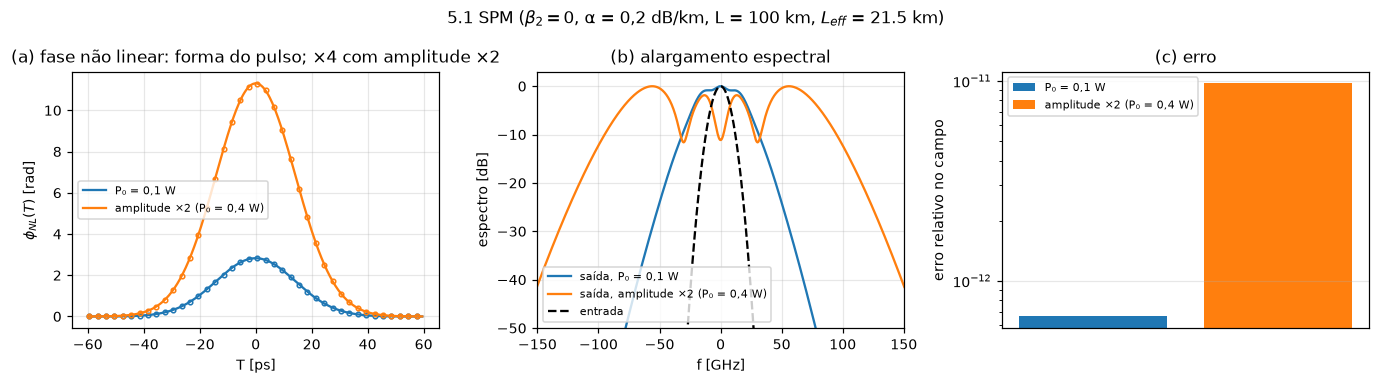

In [7]:
L5 = 100e3
Leff = (1 - np.exp(-ALPHA * L5)) / ALPHA
spm = fibra(L5, gamma=GAMMA, alpha=ALPHA, manakov=False)
casos = {"P₀ = 0,1 W": 0.1, "amplitude ×2 (P₀ = 0,4 W)": 0.4}
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.5))
saida_spm = {}
for i, (nome, P0) in enumerate(casos.items()):
    A0 = gaussiana(t, T0, P0)
    a = A0 * np.exp(-ALPHA * L5 / 2) * np.exp(1j * GAMMA * np.abs(A0) ** 2 * Leff)
    s = propagate(A0[None, :], om, spm)[0]
    saida_spm[nome] = s
    jan = np.abs(t) < 3 * T0
    ax[0].plot(t[jan] * 1e12, GAMMA * np.abs(A0[jan]) ** 2 * Leff, "-", color=C3[i],
               label=nome)
    ax[0].plot(t[jan][::6] * 1e12, np.unwrap(np.angle(s[jan] / A0[jan]))[::6], "o", ms=3,
               mfc="none", color=C3[i])
    Sin = np.fft.fftshift(np.abs(np.fft.fft(A0)) ** 2)
    Sout = np.fft.fftshift(np.abs(np.fft.fft(s)) ** 2)
    ax[1].plot(np.fft.fftshift(f) / 1e9, 10 * np.log10(Sout / Sout.max() + 1e-30), "-",
               color=C3[i], label=f"saída, {nome}")
    ax[2].bar(i, erro(a, s), color=C3[i], label=nome)
ax[1].plot(np.fft.fftshift(f) / 1e9, 10 * np.log10(Sin / Sin.max() + 1e-30), "k--",
           label="entrada")
DP = propagate(np.vstack([gaussiana(t, T0, 0.1)] * 2) / np.sqrt(2), om,
               fibra(L5, gamma=GAMMA, alpha=ALPHA, manakov=True))
fase_dp = np.angle(DP[0][N // 2] / (gaussiana(t, T0, 0.1)[N // 2] / np.sqrt(2)
                                    * np.exp(-ALPHA * L5 / 2)))
print(f"Manakov DP (mesma potência total): φ_max/φ_max escalar = "
      f"{fase_dp / (GAMMA * 0.1 * Leff):.6f}  (esperado 8/9 = {8/9:.6f})")
ax[0].set(xlabel="T [ps]", ylabel=r"$\phi_{NL}(T)$ [rad]",
          title=r"(a) fase não linear: forma do pulso; ×4 com amplitude ×2")
ax[1].set(xlim=(-150, 150), ylim=(-50, 3), xlabel="f [GHz]", ylabel="espectro [dB]",
          title="(b) alargamento espectral")
ax[2].set(yscale="log", xticks=[], ylabel="erro relativo no campo", title="(c) erro")
for a_ in ax: a_.legend()
fig.suptitle(rf"5.1 SPM ($\beta_2 = 0$, α = 0,2 dB/km, L = 100 km, $L_{{eff}}$ = {Leff/1e3:.1f} km)")
fig.tight_layout()

### 5.2 Espectrograma e frequência × distância

O espectrograma mostra o conteúdo espectral de cada trecho do pulso (transformada de
Fourier de janelas curtas). **[Dedução]** No eixo da FFT do NumPy a frequência
instantânea é $f_{FFT} = +\frac{1}{2\pi}\frac{\partial\phi_{NL}}{\partial T}$, ou seja,
$-\delta\omega/2\pi$ do Agrawal (seção 0): a borda de subida aparece em $f_{FFT} > 0$, que
é o lado vermelho. A borda de subida e a de descida deslocam a frequência em sentidos
opostos. O mapa frequência × distância mostra o espectro sendo criado ao longo da fibra.

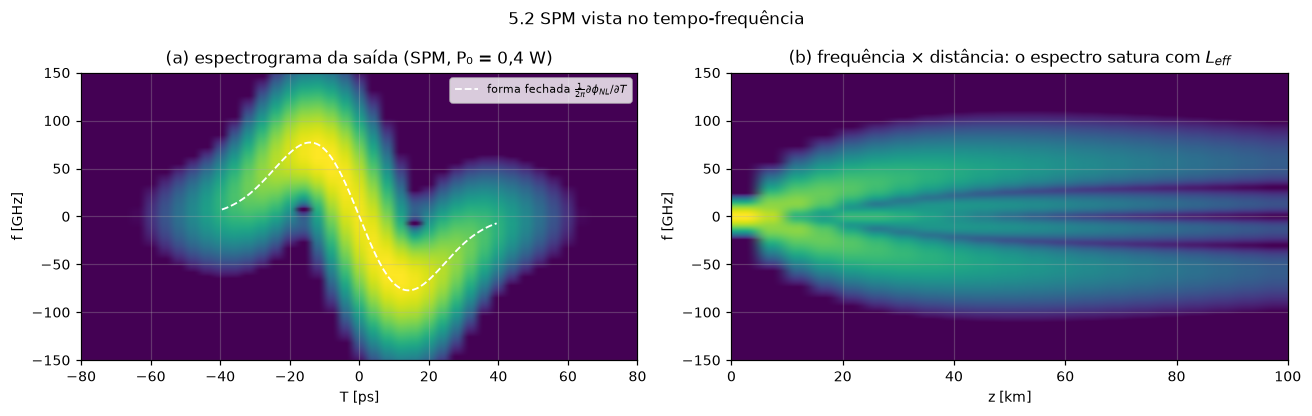

In [8]:
def espectrograma(A, t, larg=8e-12, passo=8):
    centros = t[::passo]
    w = lambda tc: np.exp(-((t - tc) / larg) ** 2)
    S = np.array([np.fft.fftshift(np.abs(np.fft.fft(A * w(tc))) ** 2) for tc in centros])
    return centros, S

P0 = 0.4
A0 = gaussiana(t, T0, P0)
s = saida_spm["amplitude ×2 (P₀ = 0,4 W)"]
tc, S = espectrograma(s, t)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ext = [tc[0] * 1e12, tc[-1] * 1e12, np.fft.fftshift(f)[0] / 1e9, np.fft.fftshift(f)[-1] / 1e9]
ax[0].imshow(10 * np.log10(S.T / S.max() + 1e-12), origin="lower", aspect="auto",
             extent=ext, vmin=-40, cmap="viridis")
finst = np.gradient(GAMMA * np.abs(A0) ** 2 * Leff, t) / (2 * np.pi)
jan = np.abs(t) < 2 * T0
ax[0].plot(t[jan] * 1e12, finst[jan] / 1e9, "w--", lw=1.2,
           label=r"forma fechada $\frac{1}{2\pi}\partial\phi_{NL}/\partial T$")
ax[0].set(xlim=(-80, 80), ylim=(-150, 150), xlabel="T [ps]", ylabel="f [GHz]",
          title="(a) espectrograma da saída (SPM, P₀ = 0,4 W)")
ax[0].legend(loc="upper right")
zmap = np.linspace(0, L5, 21)
mapa = np.array([np.fft.fftshift(np.abs(np.fft.fft(
    propagate(A0[None, :], om, fibra(z, gamma=GAMMA, alpha=ALPHA, manakov=False))[0])) ** 2)
    for z in zmap])
ax[1].imshow(10 * np.log10(mapa.T / mapa.max() + 1e-12), origin="lower", aspect="auto",
             extent=[0, L5 / 1e3, ext[2], ext[3]], vmin=-40, cmap="viridis")
ax[1].set(ylim=(-150, 150), xlabel="z [km]", ylabel="f [GHz]",
          title="(b) frequência × distância: o espectro satura com $L_{eff}$")
fig.suptitle("5.2 SPM vista no tempo-frequência")
fig.tight_layout()

**Leitura.** (a) A linha tracejada é a frequência instantânea da forma fechada e passa
pelo centro do espectrograma. (b) O alargamento é rápido no início e para de crescer
depois de alguns $L_{eff}$, porque a potência já caiu com a atenuação: a fase não
linear acumulada é $\gamma P_0 L_{eff}$, não $\gamma P_0 L$.

### 5.3 Kerr com dispersão: normal × anômala e o sóliton fundamental

Com dispersão e Kerr juntos não há forma fechada geral. **[Fato: Agrawal, texto após a
Eq. 2.6.18]** A solução numérica da NLS mostra que o alargamento induzido pela dispersão
é bem menor em dispersão anômala (β₂ < 0): o chirp da SPM (azul atrás, vermelho na
frente) compensa o da dispersão. Em dispersão normal os dois chirps se somam.

A exceção com forma fechada é o sóliton fundamental. **[Fato: Agrawal, Eq. 9.2.1–9.2.8]**
Com $N^2 = \gamma P_0 T_0^2/|\beta_2| = L_D/L_{NL}$, a entrada
$u(0,\tau) = N\,\mathrm{sech}(\tau)$ com N = 1 se propaga sem mudar de forma e só ganha
fase: $u(\xi,\tau) = \mathrm{sech}(\tau)\,e^{i\xi/2}$, com $\xi = z/L_D$ e $\tau = T/T_0$. Em
unidades do pacote:

$$A(z,T) = \sqrt{P_0}\,\mathrm{sech}(T/T_0)\,e^{iz/(2L_D)},\qquad P_0 = \frac{|\beta_2|}{\gamma T_0^2}$$

Abaixo: (a) a mesma gaussiana com N = 1 nos três casos; (b)–(c) o sóliton, comparando o
campo complexo inteiro (amplitude e fase) com a Eq. 9.2.8.

T1/T0 em z = 4 L_D: só dispersão (Eq. 2.4.17): 4.123 | SPM + dispersão anômala: 2.039 | SPM + dispersão normal (β₂ → −β₂): 5.764
fase do sóliton no pico em z = 5 L_D: 2.499997 rad (Eq. 9.2.8: ξ/2 = 2,5 rad)


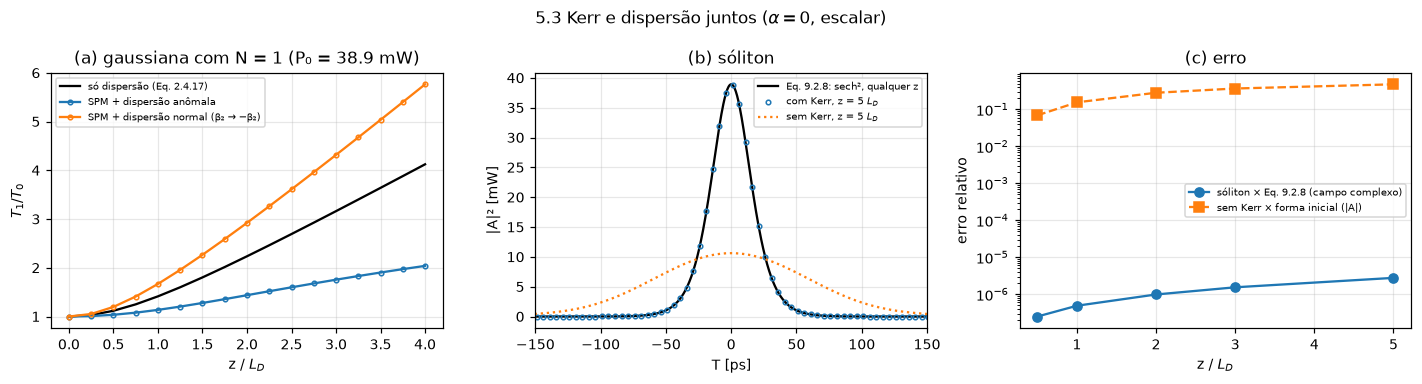

In [9]:
P_sol = abs(B2) / (GAMMA * T0 ** 2)
LD = T0 ** 2 / abs(B2)
# (a) gaussiana com N = 1: só dispersão, SPM + anômala, SPM + normal
g_N1 = gaussiana(t, T0, P_sol)
zg = np.linspace(0, 4, 17) * LD
casos_gvd = {"só dispersão (Eq. 2.4.17)": dict(beta2=B2),
             "SPM + dispersão anômala": dict(beta2=B2, gamma=GAMMA),
             "SPM + dispersão normal (β₂ → −β₂)": dict(beta2=-B2, gamma=GAMMA)}
larg_gvd = {nome: [largura(t, propagate(g_N1[None, :], om, fibra(z, manakov=False, **kw),
                                        max_step=LD / 200)[0]) / T0 if z > 0 else 1.0
                   for z in zg] for nome, kw in casos_gvd.items()}
# (b)-(c) sóliton
A_sol = np.sqrt(P_sol) / np.cosh(t / T0)
zr = np.array([0.5, 1, 2, 3, 5])
err_sol, err_lin, saida_sol = [], [], {}
for zri in zr:
    z = zri * LD
    s = propagate(A_sol[None, :], om, fibra(z, beta2=B2, gamma=GAMMA, manakov=False),
                  max_step=LD / 400)[0]
    l = propagate(A_sol[None, :], om, fibra(z, beta2=B2), max_step=LD / 400)[0]
    saida_sol[zri] = (s, l)
    err_sol.append(erro(A_sol * np.exp(1j * z / (2 * LD)), s))
    err_lin.append(erro(np.abs(A_sol), np.abs(l)))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
for i, (nome, w) in enumerate(larg_gvd.items()):
    ax[0].plot(zg / LD, w, "o-" if i else "-", ms=3, mfc="none", color=["k", C3[0], C3[1]][i],
               label=nome)
ax[0].set(xlabel="z / $L_D$", ylabel="$T_1/T_0$",
          title=f"(a) gaussiana com N = 1 (P₀ = {P_sol*1e3:.1f} mW)")
s5, l5 = saida_sol[5.0]
ax[1].plot(t * 1e12, np.abs(A_sol) ** 2 * 1e3, "k-", label="Eq. 9.2.8: sech², qualquer z")
ax[1].plot(t[::10] * 1e12, np.abs(s5[::10]) ** 2 * 1e3, "o", ms=3, mfc="none", color=C3[0],
           label="com Kerr, z = 5 $L_D$")
ax[1].plot(t * 1e12, np.abs(l5) ** 2 * 1e3, ":", color=C3[1], label="sem Kerr, z = 5 $L_D$")
ax[1].set(xlim=(-150, 150), xlabel="T [ps]", ylabel="|A|² [mW]", title="(b) sóliton")
ax[2].semilogy(zr, err_sol, "o-", color=C3[0], label="sóliton × Eq. 9.2.8 (campo complexo)")
ax[2].semilogy(zr, err_lin, "s--", color=C3[1], label="sem Kerr × forma inicial (|A|)")
ax[2].set(xlabel="z / $L_D$", ylabel="erro relativo", title="(c) erro")
for a_ in ax: a_.legend(fontsize=6.5)
fig.suptitle(r"5.3 Kerr e dispersão juntos ($\alpha = 0$, escalar)")
fig.tight_layout()
print("T1/T0 em z = 4 L_D: " + " | ".join(f"{k}: {v[-1]:.3f}" for k, v in larg_gvd.items()))
print(f"fase do sóliton no pico em z = 5 L_D: {np.angle(s5[N // 2]):.6f} rad "
      f"(Eq. 9.2.8: ξ/2 = 2,5 rad)")

**Leitura.** (Os números citados estão na saída da célula.)
- (a) A mesma gaussiana alarga 4,1 vezes em $4L_D$ só com dispersão (a Eq. 2.4.17, que a
  linha sem marcadores reproduz), 2,0 vezes com SPM em dispersão anômala e 5,8 vezes em
  dispersão normal: o que o Agrawal descreve após a Eq. 2.6.18.
- (b) Sem Kerr o sóliton alarga; com Kerr ele mantém a forma sech².
- (c) O campo complexo, inclusive a fase $z/(2L_D)$ da Eq. 9.2.8, fica a ~1e-6 da forma
  fechada. Esse erro não é de arredondamento: é o erro de separação do split-step, que
  existe quando dispersão e Kerr atuam juntos e diminui com o passo (seção 6).

Testes que garantem: `test_03_nao_linearidade.py` (SPM, 8/9) e `test_05_soliton.py`.

### 5.4 Modulação de fase cruzada (XPM)

**Conceito.** Com dois canais na fibra, o índice de refração depende da potência total:
cada canal ganha fase pela própria potência (SPM) e pela do outro (XPM).

**[Fato: Agrawal, Eq. 2.6.16]** O deslocamento de fase do canal j é

$$\phi_j^{NL} = \gamma L_{eff}\Big(P_j + 2\sum_{m\neq j}P_m\Big)$$

O fator 2 indica que a XPM é duas vezes mais eficaz que a SPM para a mesma potência.
**[Fato: Agrawal, texto após a Eq. 2.6.17]** A expressão supõe que a XPM age isolada, sem
efeitos dispersivos, e vale para feixes CW. Por isso o teste usa dois tons CW: uma bomba
de 100 mW em −100 GHz e uma sonda de 1 mW em +100 GHz (eixo da FFT), com a atenuação e a
dispersão da fibra padrão. A dispersão é necessária: ela descasa a fase da FWM entre os
dois tons (seção 5.5), que de outra forma também mexeria na sonda.

A fase de cada tom é lida no seu bin da FFT, descontando a fase linear da dispersão,
$\beta_2\omega_k^2 z/2$ (seção 3).

z = 100 km: sonda 5.6647 rad (Eq. 2.6.16: 5.6834) | bomba 2.8839 rad (2.8841) | sonda com β₂ = 0: potência ×8.2


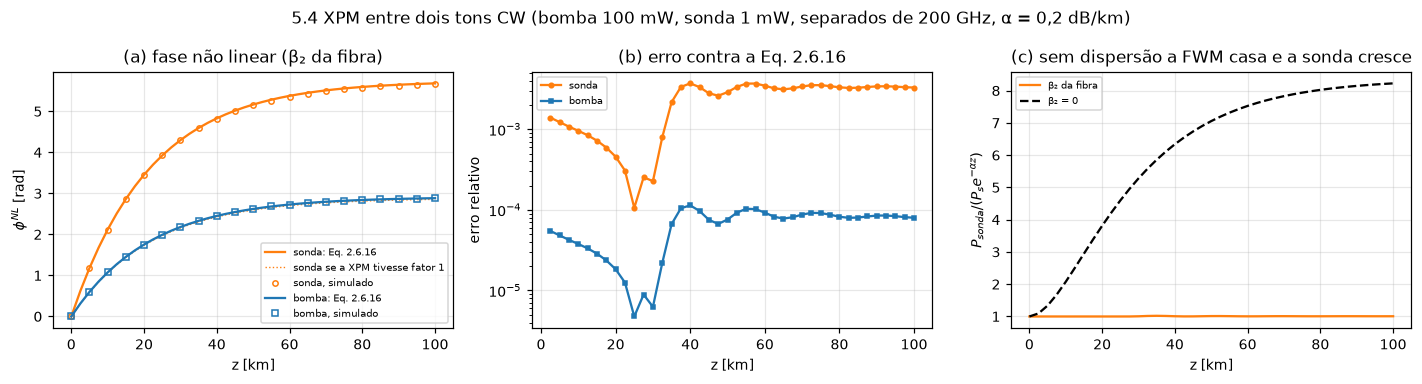

In [10]:
Nf, FSf = 2 ** 10, 1.024e12                     # resolução de 1 GHz: tons em bins exatos
tf, ff, omf = grade(Nf, FSf)
fb, fs_ = -100e9, 100e9
kb, ks = np.argmin(np.abs(ff - fb)), np.argmin(np.abs(ff - fs_))
Pb, Ps = 100e-3, 1e-3
A_xpm = np.sqrt(Pb) * np.exp(2j * np.pi * fb * tf) + np.sqrt(Ps) * np.exp(2j * np.pi * fs_ * tf)
zx = np.linspace(0, 100e3, 41)

def tons_ao_longo(A0, b2):
    """Fase não linear de cada tom e potência da sonda ao longo de z, propagando trecho a trecho."""
    A, S0 = A0.copy(), np.fft.fft(A0)
    fases, pot_s = [], []
    for k, z in enumerate(zx):
        if k > 0:
            A = propagate(A[None, :], omf, fibra(zx[k] - zx[k - 1], beta2=b2, gamma=GAMMA,
                                                 alpha=ALPHA, manakov=False), max_step=200.0)[0]
        S = np.fft.fft(A)
        fases.append([np.angle(S[i] / S0[i] * np.exp(-0.5j * b2 * omf[i] ** 2 * z)) for i in (kb, ks)])
        pot_s.append(np.abs(S[ks] / Nf) ** 2)
    return np.unwrap(np.array(fases), axis=0), np.array(pot_s)

fase_d, pot_d = tons_ao_longo(A_xpm, B2)
fase_0, pot_0 = tons_ao_longo(A_xpm, 0.0)
Leff_x = (1 - np.exp(-ALPHA * zx)) / ALPHA
ana_b = GAMMA * Leff_x * (Pb + 2 * Ps)
ana_s = GAMMA * Leff_x * (Ps + 2 * Pb)

fig, ax = plt.subplots(1, 3, figsize=(13, 3.5))
ax[0].plot(zx / 1e3, ana_s, "-", color=C3[1], label="sonda: Eq. 2.6.16")
ax[0].plot(zx / 1e3, GAMMA * Leff_x * (Ps + Pb), ":", color=C3[1], lw=0.9,
           label="sonda se a XPM tivesse fator 1")
ax[0].plot(zx[::2] / 1e3, fase_d[::2, 1], "o", ms=3.5, mfc="none", color=C3[1], label="sonda, simulado")
ax[0].plot(zx / 1e3, ana_b, "-", color=C3[0], label="bomba: Eq. 2.6.16")
ax[0].plot(zx[::2] / 1e3, fase_d[::2, 0], "s", ms=3.5, mfc="none", color=C3[0], label="bomba, simulado")
ax[0].set(xlabel="z [km]", ylabel=r"$\phi^{NL}$ [rad]", title="(a) fase não linear (β₂ da fibra)")
ax[1].semilogy(zx[1:] / 1e3, np.abs(fase_d[1:, 1] - ana_s[1:]) / ana_s[1:], "o-", ms=3,
               color=C3[1], label="sonda")
ax[1].semilogy(zx[1:] / 1e3, np.abs(fase_d[1:, 0] - ana_b[1:]) / ana_b[1:], "s-", ms=3,
               color=C3[0], label="bomba")
ax[1].set(xlabel="z [km]", ylabel="erro relativo", title="(b) erro contra a Eq. 2.6.16")
ax[2].plot(zx / 1e3, pot_d / (Ps * np.exp(-ALPHA * zx)), "-", color=C3[1], label="β₂ da fibra")
ax[2].plot(zx / 1e3, pot_0 / (Ps * np.exp(-ALPHA * zx)), "--", color="k", label="β₂ = 0")
ax[2].set(xlabel="z [km]", ylabel=r"$P_{sonda}/(P_s e^{-\alpha z})$",
          title="(c) sem dispersão a FWM casa e a sonda cresce")
for a_ in ax: a_.legend(fontsize=6.5)
fig.suptitle("5.4 XPM entre dois tons CW (bomba 100 mW, sonda 1 mW, separados de 200 GHz, α = 0,2 dB/km)")
fig.tight_layout()
print(f"z = 100 km: sonda {fase_d[-1, 1]:.4f} rad (Eq. 2.6.16: {ana_s[-1]:.4f}) | "
      f"bomba {fase_d[-1, 0]:.4f} rad ({ana_b[-1]:.4f}) | sonda com β₂ = 0: "
      f"potência ×{pot_0[-1] / (Ps * np.exp(-ALPHA * 100e3)):.1f}")

**Leitura.** (Os números citados estão na saída da célula.)
- (a) A fase da sonda é quase toda XPM, e segue a Eq. 2.6.16 com o fator 2; com fator 1
  ela ficaria pela metade (o pontilhado, quase em cima da curva da bomba). A bomba quase
  só tem SPM, porque a sonda é fraca. As duas fases saturam com $L_{eff}$, como na SPM.
- (b) A bomba fica a ~1e-4 da Eq. 2.6.16; a sonda, a ~0,3 %. O que sobra na sonda é a FWM
  residual: com a dispersão da fibra ela é descasada, mas não zero.
- (c) Sem dispersão a FWM entre bomba e sonda fica casada em fase e a sonda ganha potência
  (8 vezes em 100 km): a Eq. 2.6.16 deixa de valer. É a ressalva do Agrawal de que a
  expressão supõe XPM agindo isolada.

Sem teste no pytest ainda (a XPM é consequência do mesmo termo $\gamma|A|^2A$ testado na
SPM; um teste próprio é candidato para a issue de testes da fibra).

### 5.5 Mistura de quatro ondas (FWM) entre tons

**Conceito.** Com dois tons em $f_1$ e $f_2$, o termo $|A|^2A$ contém produtos
$A_1^2A_2^*$, que oscilam em $2f_1-f_2$: o Kerr cria frequências novas. Esses produtos
misturam de novo com os tons originais e geram $3f_1-2f_2$, e assim por diante (cascata).

**[Fato: Agrawal, Eq. 6.3.16–6.3.19]** Desprezando a SPM e a XPM dos tons e a depleção, a
potência transferida para $\omega_F = \omega_i + \omega_j - \omega_k$ é

$$P_F = \eta_F\,(d_F\gamma L)^2 P_iP_jP_k\,e^{-\alpha L},\qquad
\eta_F = \left|\frac{1-e^{-(\alpha+i\Delta k)L}}{(\alpha+i\Delta k)L}\right|^2,\qquad
\Delta k \approx \beta_2(\omega_i-\omega_k)(\omega_j-\omega_k)$$

com o fator de degenerescência $d_F = 1$ se $i = j$. **[Dedução]** Para $2f_1 - f_2$
($i = j = 1$, $k = 2$): $d_F = 1$ e $\Delta k = \beta_2\Omega^2$, com $\Omega = 2\pi(f_2 - f_1)$,
o descasamento de fase da Eq. 2.6.19. Sem perda, $\eta_F = \mathrm{sinc}^2(\Delta k L/2)$.

Sem dispersão (Δk = 0) a componente nova cresce com $L_{eff}^2$. Com dispersão, as ondas
perdem a relação de fase depois do comprimento de coerência $2\pi/\Delta k$: a energia vai e
volta e não se acumula. A aproximação de pequeno sinal despreza a fase da SPM/XPM dos
próprios tons; o erro relativo resultante cresce como $(\gamma P L)^2$, o que o painel (c)
mostra.

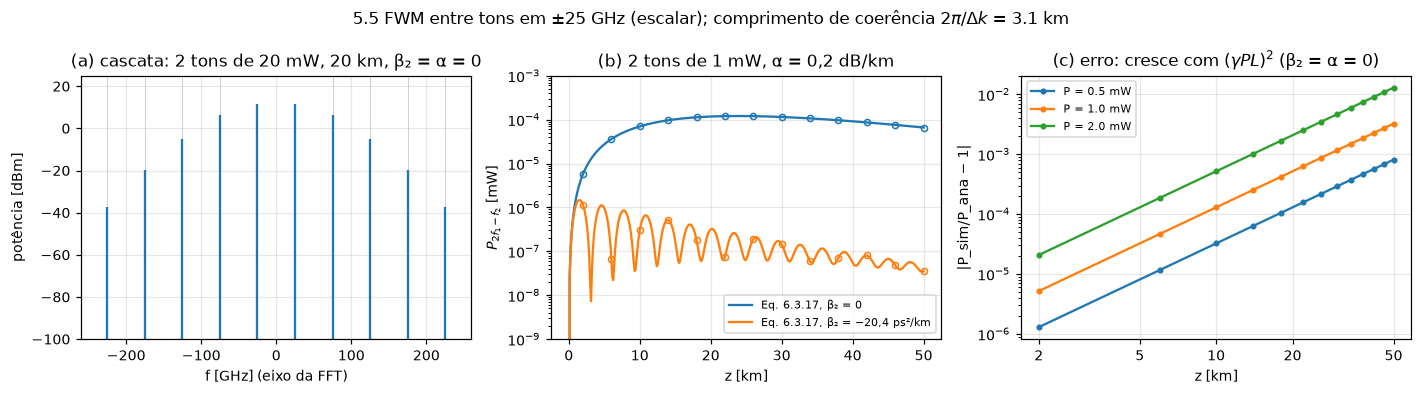

In [11]:
f1, f2 = -25e9, 25e9
k3 = np.argmin(np.abs(ff - (2 * f1 - f2)))
tons = lambda P: (np.sqrt(P) * np.exp(2j * np.pi * f1 * tf)
                  + np.sqrt(P) * np.exp(2j * np.pi * f2 * tf))
pot = lambda A, k: np.abs(np.fft.fft(A)[k] / Nf) ** 2

def p_fwm(z, b2, a, P):
    """Agrawal, Eq. 6.3.17-6.3.19, caso degenerado (d_F = 1), três potências iguais a P."""
    z = np.asarray(z, dtype=float)
    x = (a + 1j * b2 * (2 * np.pi * (f2 - f1)) ** 2) * z
    with np.errstate(invalid="ignore", divide="ignore"):
        eta = np.where(np.abs(x) > 0, np.abs((1 - np.exp(-x)) / x) ** 2, 1.0)   # x → 0: η → 1
    return eta * (GAMMA * z) ** 2 * P ** 3 * np.exp(-a * z)

dbeta = abs(B2) * (2 * np.pi * (f2 - f1)) ** 2
zf = np.linspace(2e3, 50e3, 13)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
# (a) cascata
s = propagate(tons(20e-3)[None, :], omf, fibra(20e3, gamma=GAMMA, manakov=False),
              max_step=100.0)[0]
Sp = np.abs(np.fft.fftshift(np.fft.fft(s)) / Nf) ** 2
ax[0].stem(np.fft.fftshift(ff) / 1e9, 10 * np.log10(Sp * 1e3 + 1e-30), bottom=-120,
           markerfmt=" ", basefmt=" ")
for m in range(1, 5):
    ax[0].axvline(((m + 1) * f1 - m * f2) / 1e9, color="0.8", lw=0.6, zorder=0)
    ax[0].axvline(((m + 1) * f2 - m * f1) / 1e9, color="0.8", lw=0.6, zorder=0)
ax[0].set(xlim=(-260, 260), ylim=(-100, 25), xlabel="f [GHz] (eixo da FFT)",
          ylabel="potência [dBm]", title="(a) cascata: 2 tons de 20 mW, 20 km, β₂ = α = 0")
# (b) crescimento com e sem dispersão, com perda
zz = np.linspace(0, 50e3, 400)
for i, (b2, nome) in enumerate([(0.0, "β₂ = 0"), (B2, "β₂ = −20,4 ps²/km")]):
    simf = [pot(propagate(tons(1e-3)[None, :], omf, fibra(z, beta2=b2, gamma=GAMMA, alpha=ALPHA,
                                                          manakov=False), max_step=100.0)[0], k3)
            for z in zf]
    ax[1].semilogy(zz / 1e3, p_fwm(zz, b2, ALPHA, 1e-3) * 1e3 + 1e-30, "-", color=C3[i],
                   label=f"Eq. 6.3.17, {nome}")
    ax[1].semilogy(zf / 1e3, np.array(simf) * 1e3, "o", ms=4, mfc="none", color=C3[i])
ax[1].set(ylim=(1e-9, 1e-3), xlabel="z [km]", ylabel=r"$P_{2f_1-f_2}$ [mW]",
          title="(b) 2 tons de 1 mW, α = 0,2 dB/km")
# (c) erro da aproximação de pequeno sinal
for i, P in enumerate([0.5e-3, 1e-3, 2e-3]):
    e = [abs(pot(propagate(tons(P)[None, :], omf, fibra(z, gamma=GAMMA, manakov=False),
                           max_step=100.0)[0], k3) / p_fwm(z, 0.0, 0.0, P) - 1) for z in zf]
    ax[2].loglog(zf / 1e3, e, "o-", ms=3, color=C3[i], label=f"P = {P*1e3:.1f} mW")
eixo_log_legivel(ax[2], [2, 5, 10, 20, 50])
ax[2].set(xlabel="z [km]", ylabel="|P_sim/P_ana − 1|",
          title=r"(c) erro: cresce com $(\gamma P L)^2$ (β₂ = α = 0)")
for a_ in ax[1:]: a_.legend()
fig.suptitle(rf"5.5 FWM entre tons em ±25 GHz (escalar); comprimento de coerência "
             rf"$2\pi/\Delta k$ = {2*np.pi/dbeta/1e3:.1f} km")
fig.tight_layout()

**Leitura.** (a) Os produtos aparecem nas posições previstas (linhas cinzas) e caem em
potência a cada ordem da cascata. (b) Sem dispersão a componente cresce com $L_{eff}^2$ e
satura com a perda; com a dispersão da fibra padrão ela oscila com período igual ao
comprimento de coerência e fica ordens de grandeza abaixo. **[Fato: Agrawal, texto após a
Eq. 6.3.19]** Com $|\beta_2| > 5$ ps²/km a eficiência praticamente se anula para canais a
50 GHz; perto do zero de dispersão ela vai a 1: é por isso que a FWM pesa pouco em fibra
padrão e muito em fibra de dispersão deslocada. (c) O erro escala com o quadrado da
potência e da distância, como esperado da aproximação.

Pendência registrada: o arquivo VPI de referência tem `FWM = No`, e o SSFM de campo
agregado não tem como desligar a FWM (decisão aberta D-21).

### 5.6 FWM com pulsos: só há geração enquanto eles se sobrepõem

O caso da aula: com pulsos em vez de tons, a FWM aparece onde os pulsos de canais
diferentes se sobrepõem no tempo e para quando eles se separam.

**[Dedução, da Eq. 2.4.4]** Como $\beta_1 = d\beta/d\omega$ varia com a frequência,
$\beta_1(\omega_0 + \Delta\omega) = \beta_1 + \beta_2\Delta\omega$: dois canais separados de
Ω se afastam (ou se aproximam) no tempo à taxa $|\beta_2|\Omega$ por unidade de comprimento.
**[Dedução, da seção 3]** No eixo da FFT, a componente em +f atrasa
$-\beta_2\,2\pi f\,z$; com β₂ < 0, o canal em +f anda para trás no tempo.

Montagem: dois pulsos gaussianos de 20 ps e 20 mW, em −50 e +50 GHz (eixo da FFT),
começando 200 ps separados, o de +50 GHz na frente. Com
$|\beta_2|\Omega$ = 12,9 ps/km eles se cruzam em $z_c$ = 15,5 km. Sem perda, para isolar o
efeito. O controle é a mesma montagem com β₂ = 0: os pulsos não se movem, nunca se
sobrepõem, e não deve haver FWM. A medida é a energia na banda de ±15 GHz em torno de
$2f_1 - f_2$ = −150 GHz; a sobreposição é $\int I_1 I_2\,dT$ dos dois canais filtrados.

walk-off |β₂|Ω = 12.86 ps/km; z_c = 15.55 km
energia de FWM: máxima 2.24e-06 em z = 15.5 km; no fim (40 km) 2.43e-11; sem colisão (β₂ = 0) no fim 5.14e-11


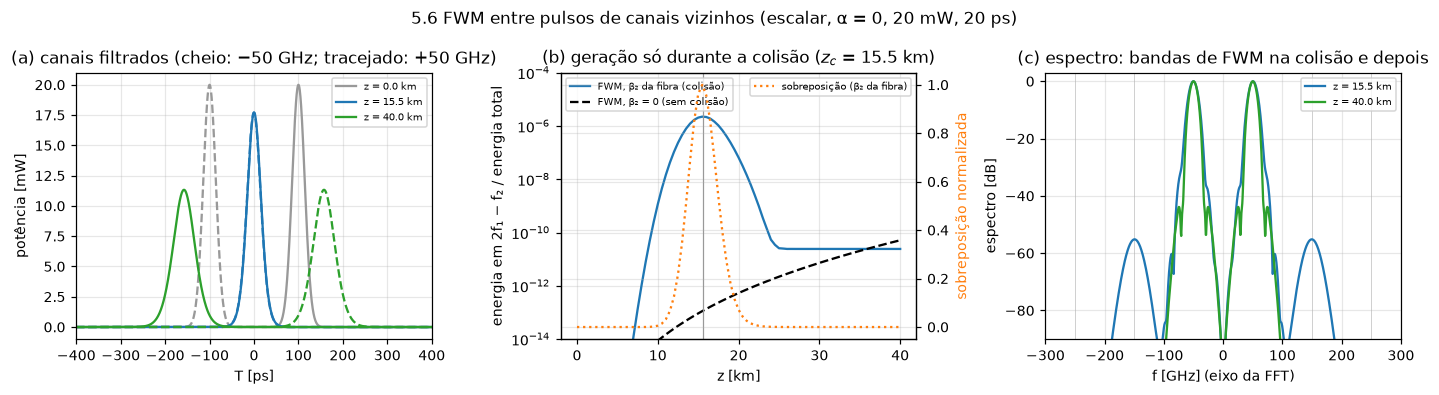

In [12]:
Np, FSp = 2 ** 12, 2e12
tp, fp_, omp = grade(Np, FSp)
T0p6, sep6, P6 = 20e-12, 200e-12, 20e-3
f1p, f2p = -50e9, 50e9
A1 = gaussiana(tp - sep6 / 2, T0p6, P6) * np.exp(2j * np.pi * f1p * tp)
A2 = gaussiana(tp + sep6 / 2, T0p6, P6) * np.exp(2j * np.pi * f2p * tp)
banda = lambda fc, w: np.abs(fp_ - fc) < w
filtra = lambda A, m: np.fft.ifft(np.fft.fft(A) * m)
E_total = np.sum(np.abs(np.fft.fft(A1 + A2)) ** 2)
d_walk = abs(B2) * 2 * np.pi * (f2p - f1p)
z_c = sep6 / d_walk
zp6 = np.linspace(0, 40e3, 81)

def colisao(b2):
    A, E, ov, perfis = A1 + A2, [], [], {}
    for k, z in enumerate(zp6):
        if k > 0:
            A = propagate(A[None, :], omp, fibra(zp6[k] - zp6[k - 1], beta2=b2, gamma=GAMMA,
                                                 manakov=False), max_step=100.0)[0]
        S = np.fft.fft(A)
        E.append(np.sum(np.abs(S[banda(2 * f1p - f2p, 15e9)]) ** 2) / E_total)
        I1 = np.abs(filtra(A, banda(f1p, 40e9))) ** 2
        I2 = np.abs(filtra(A, banda(f2p, 40e9))) ** 2
        ov.append(np.sum(I1 * I2))
        perfis[k] = (I1, I2, np.abs(S) ** 2)
    return np.array(E), np.array(ov), perfis

E_d, ov_d, perf_d = colisao(B2)
E_0, ov_0, _ = colisao(0.0)
k_c = np.argmin(np.abs(zp6 - z_c))

fig, ax = plt.subplots(1, 3, figsize=(13, 3.6))
for i, (k, cor) in enumerate([(0, "0.6"), (k_c, C3[0]), (len(zp6) - 1, C3[2])]):
    I1, I2, _ = perf_d[k]
    ax[0].plot(tp * 1e12, I1 * 1e3, "-", color=cor, label=f"z = {zp6[k]/1e3:.1f} km")
    ax[0].plot(tp * 1e12, I2 * 1e3, "--", color=cor)
ax[0].set(xlim=(-400, 400), xlabel="T [ps]", ylabel="potência [mW]",
          title="(a) canais filtrados (cheio: −50 GHz; tracejado: +50 GHz)")
ax[0].legend(fontsize=6.5)
ax[1].semilogy(zp6 / 1e3, E_d, "-", color=C3[0], label="FWM, β₂ da fibra (colisão)")
ax[1].semilogy(zp6 / 1e3, E_0, "--", color="k", label="FWM, β₂ = 0 (sem colisão)")
ax1b = ax[1].twinx()
ax1b.plot(zp6 / 1e3, ov_d / ov_d.max(), ":", color=C3[1], label="sobreposição (β₂ da fibra)")
ax1b.set_ylabel("sobreposição normalizada", color=C3[1])
ax[1].axvline(z_c / 1e3, color="0.6", lw=0.8)
ax[1].set(ylim=(1e-14, 1e-4), xlabel="z [km]", ylabel="energia em 2f₁ − f₂ / energia total",
          title=f"(b) geração só durante a colisão ($z_c$ = {z_c/1e3:.1f} km)")
ax[1].legend(loc="upper left", fontsize=6.5); ax1b.legend(loc="upper right", fontsize=6.5)
for k, cor in [(k_c, C3[0]), (len(zp6) - 1, C3[2])]:
    Sk = np.fft.fftshift(perf_d[k][2])
    ax[2].plot(np.fft.fftshift(fp_) / 1e9, 10 * np.log10(Sk / Sk.max() + 1e-30), color=cor,
               label=f"z = {zp6[k]/1e3:.1f} km")
for m in (1, 2):
    ax[2].axvline(((m + 1) * f1p - m * f2p) / 1e9, color="0.8", lw=0.6, zorder=0)
    ax[2].axvline(((m + 1) * f2p - m * f1p) / 1e9, color="0.8", lw=0.6, zorder=0)
ax[2].set(xlim=(-300, 300), ylim=(-90, 3), xlabel="f [GHz] (eixo da FFT)", ylabel="espectro [dB]",
          title="(c) espectro: bandas de FWM na colisão e depois")
ax[2].legend(fontsize=6.5)
fig.suptitle("5.6 FWM entre pulsos de canais vizinhos (escalar, α = 0, 20 mW, 20 ps)")
fig.tight_layout()
print(f"walk-off |β₂|Ω = {d_walk*1e15:.2f} ps/km; z_c = {z_c/1e3:.2f} km")
print(f"energia de FWM: máxima {E_d.max():.2e} em z = {zp6[np.argmax(E_d)]/1e3:.1f} km; "
      f"no fim (40 km) {E_d[-1]:.2e}; sem colisão (β₂ = 0) no fim {E_0[-1]:.2e}")

**Leitura.** (Os números citados estão na saída da célula.)
- (a) Os dois canais se aproximam, se cruzam em $z_c$ e se afastam. Também alargam pela
  dispersão ($L_D$ = 19,5 km), mas se separam antes de alargar muito.
- (b) A energia em $2f_1 - f_2$ só cresce enquanto há sobreposição (curva pontilhada) e
  tem o máximo no cruzamento. Depois que os pulsos se separam ela cai e fica constante: não
  há geração nova. **[Fato: verificado rodando]** O que sobra no fim é cinco ordens de
  grandeza abaixo do pico: a FWM gerada na aproximação é quase toda devolvida na
  separação. Sem colisão (β₂ = 0) os pulsos nunca se sobrepõem e quase nada é gerado; o
  pouco que aparece (e cresce devagar) vem do alargamento espectral por SPM de cada canal,
  que encosta na banda medida. Esse piso é do mesmo tamanho da sobra depois da colisão.
- (c) No cruzamento aparecem as bandas de FWM em ±150 GHz (e a cascata em ±250 GHz); no
  fim elas quase sumiram.

Sem forma fechada para o caso com pulsos; o tempo do cruzamento é a dedução acima.

## 6. Todos os efeitos juntos

Com α, β₂, γ e PMD ligados não há forma fechada para o campo. Duas propriedades
continuam exatas:

1. **Energia.** Dispersão, Kerr e PMD conservam energia; só a atenuação a retira. Dessa
   forma $E(L) = E(0)\,e^{-\alpha L}$ vale com todos os termos ligados.
2. **Ordem de convergência.** O split-step simétrico tem erro global proporcional a
   $h^2$ (h = passo). Comparando com uma referência de passo muito pequeno, o erro deve
   cair 4× quando o passo cai 2×.

A convergência é medida sem PMD: a realização sorteada depende da sequência de passos,
então mudar o passo muda a realização e a comparação deixa de fazer sentido.

E(L)/E(0) = 0.025118864315  |  e^(-αL) = 0.025118864315  |  erro relativo = 3.2e-14


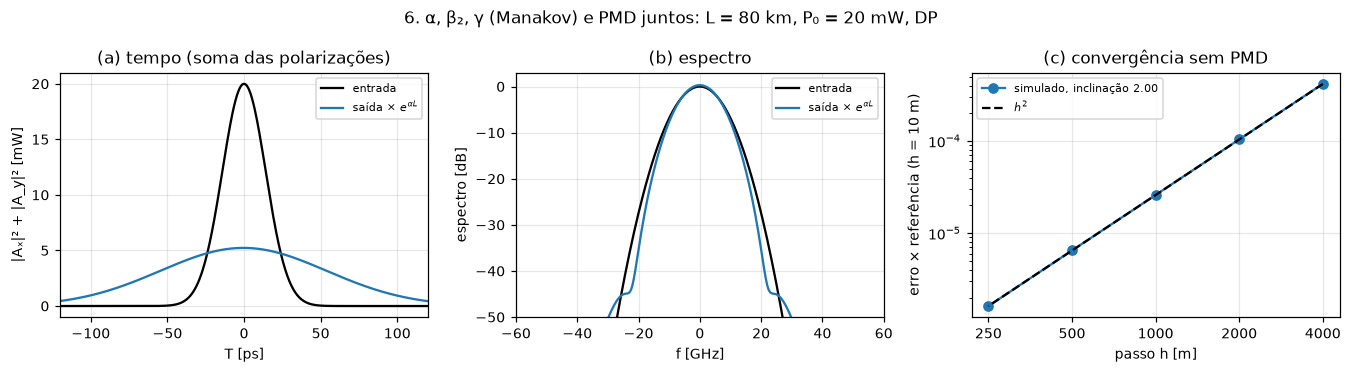

In [13]:
P0 = 20e-3
A6 = np.vstack([gaussiana(t, T0, P0)] * 2) / np.sqrt(2)
L6 = 80e3
tudo = fibra(L6, beta2=B2, gamma=GAMMA, alpha=ALPHA, pmd_coefficient=0.1e-12 / np.sqrt(1e3))
s6 = propagate(A6, om, tudo, rng=np.random.default_rng(3))
print(f"E(L)/E(0) = {energia(s6, dt)/energia(A6, dt):.12f}  |  "
      f"e^(-αL) = {np.exp(-ALPHA*L6):.12f}  |  erro relativo = "
      f"{abs(energia(s6, dt)/energia(A6, dt)/np.exp(-ALPHA*L6) - 1):.1e}")

sem_pmd = fibra(L6, beta2=B2, gamma=GAMMA, alpha=ALPHA)
ref = propagate(A6, om, sem_pmd, max_step=10.0, max_phase_deg=1e9)
hs = np.array([4000, 2000, 1000, 500, 250])
errs = [erro(ref, propagate(A6, om, sem_pmd, max_step=h, max_phase_deg=1e9)) for h in hs]
inc = np.polyfit(np.log(hs), np.log(errs), 1)[0]

fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.4))
ax[0].plot(t * 1e12, np.sum(np.abs(A6) ** 2, axis=0) * 1e3, "k-", label="entrada")
ax[0].plot(t * 1e12, np.sum(np.abs(s6) ** 2, axis=0) * 1e3 / np.exp(-ALPHA * L6), "-",
           color=C3[0], label="saída × $e^{\\alpha L}$")
ax[0].set(xlim=(-120, 120), xlabel="T [ps]", ylabel="|Aₓ|² + |A_y|² [mW]",
          title="(a) tempo (soma das polarizações)")
Sin = np.fft.fftshift(np.sum(np.abs(np.fft.fft(A6, axis=1)) ** 2, axis=0))
Sout = np.fft.fftshift(np.sum(np.abs(np.fft.fft(s6, axis=1)) ** 2, axis=0))
ax[1].plot(np.fft.fftshift(f) / 1e9, 10 * np.log10(Sin / Sin.max() + 1e-30), "k-",
           label="entrada")
ax[1].plot(np.fft.fftshift(f) / 1e9,
           10 * np.log10(Sout / Sin.max() / np.exp(-ALPHA * L6) + 1e-30),
           "-", color=C3[0], label="saída × $e^{\\alpha L}$")
ax[1].set(xlim=(-60, 60), ylim=(-50, 3), xlabel="f [GHz]", ylabel="espectro [dB]",
          title="(b) espectro")
ax[2].loglog(hs, errs, "o-", color=C3[0], label=f"simulado, inclinação {inc:.2f}")
ax[2].loglog(hs, errs[-1] * (hs / hs[-1]) ** 2, "k--", label="$h^2$")
eixo_log_legivel(ax[2], hs)
ax[2].set(xlabel="passo h [m]", ylabel="erro × referência (h = 10 m)",
          title="(c) convergência sem PMD")
for a_ in ax: a_.legend()
fig.suptitle("6. α, β₂, γ (Manakov) e PMD juntos: L = 80 km, P₀ = 20 mW, DP")
fig.tight_layout()

**Leitura.** A energia segue $e^{-\alpha L}$ no arredondamento mesmo com todos os efeitos
ligados. O erro cai com inclinação próxima de 2, a ordem do split-step simétrico; uma
inclinação próxima de 1 indicaria o esquema assimétrico (mutação 6 do
`scripts/mutacoes.py`).

Testes que garantem: `test_05_soliton.py` (ordem de convergência) e os testes de
conservação de energia.